In [1]:
import pandas as pd
import numpy as np

from utils.load_splits import load_splits
from utils.eval_tools import compare_models, bootstrap_compare, compare_by_segment, plot_comparison, plot_segments, plot_bootstrap, build_truth
from models.r1_recent import R1RecentModel
from models.recency_frequency import RecencyFrequencyModel
from models.cat_repurchase import CategoryRepurchaseModel

In [2]:
train_raw, val_raw, test_raw=load_splits(
    train_path="../../data/split/train.parquet",
    val_path="../../data/split/val.parquet",
    test_path="../../data/split/test.parquet",
)

train = train_raw[train_raw['sales_channel_id']==2]
val = val_raw[val_raw['sales_channel_id']==2]
test = test_raw[test_raw['sales_channel_id']==2]

In [3]:
articles=pd.read_parquet("../../data/cleaned_art.parquet")
types = articles.set_index("article_id")["product_type_no"] #product type

In [4]:
models = {
    "r1_recent": R1RecentModel(),
    "rf_7_nocap": RecencyFrequencyModel(half_life_days=7, history_cap_days=10000),
    "rf_7_365": RecencyFrequencyModel(half_life_days=7),
    "cat_repurchase": CategoryRepurchaseModel(types, horizon_days=7),
}

In [5]:
summary, per_user = compare_models(models, train, val, baseline="r1_recent",
                                   problem="buy_again", k=12)

Setup: user_group=warm, truth_mode=repeat -> 813 users, 1,022 relevant purchases
        0.0% of relevant purchases are articles never seen in history (no history-based model can reach them)
Evaluating r1_recent ...
Evaluating rf_7_nocap ...
Evaluating rf_7_365 ...
Evaluating cat_repurchase ...


In [6]:
ci_df, paired_df=bootstrap_compare(per_user, baseline="r1_recent", k=12)

In [18]:
#exporting
summary.to_csv("results/summary.csv")
paired_df.to_csv("results/paired_df.csv")

### **PLOTTING**

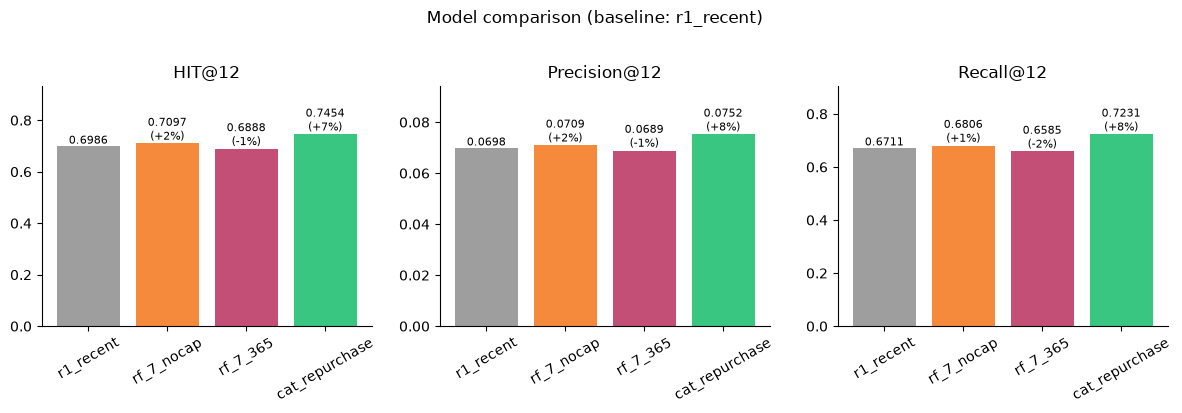

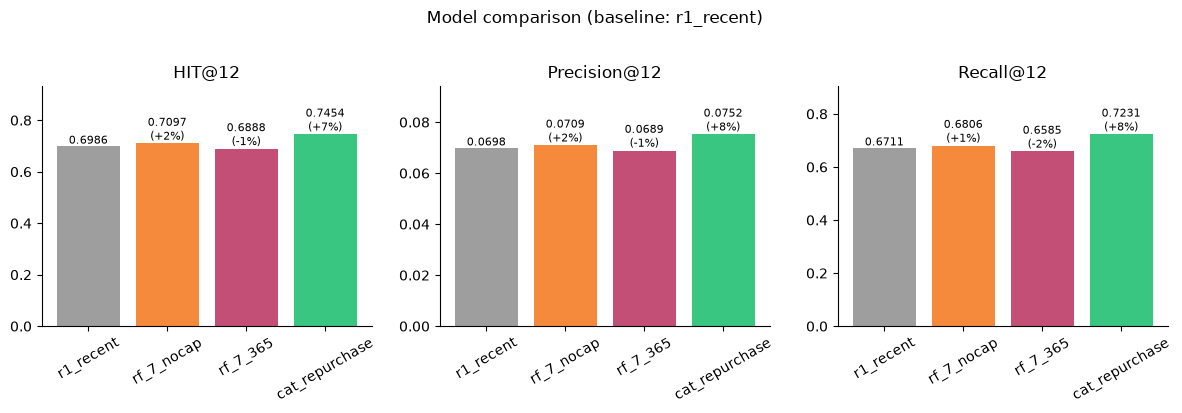

In [8]:
plot_comparison(summary, baseline="r1_recent", k=12, save_path="figures/model_comparison")

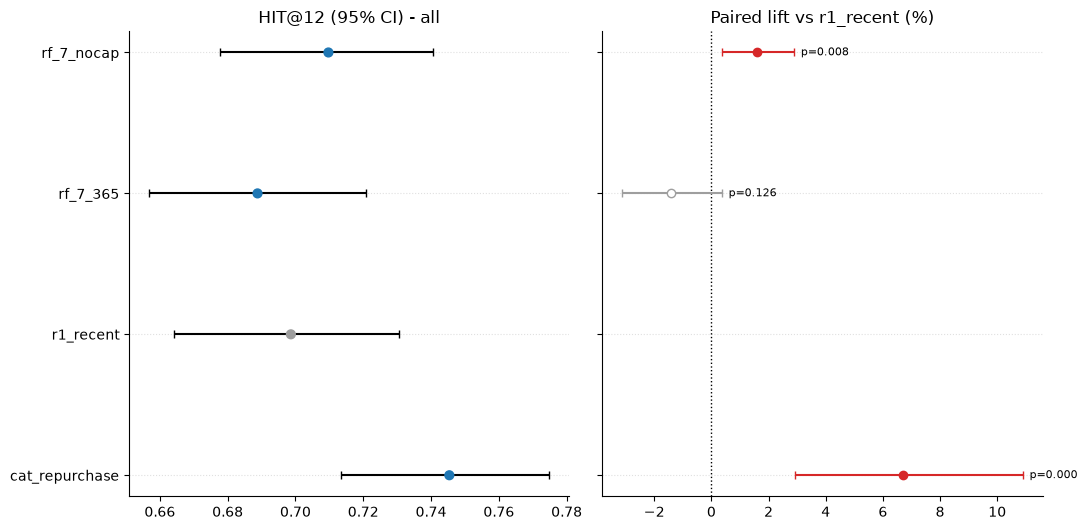

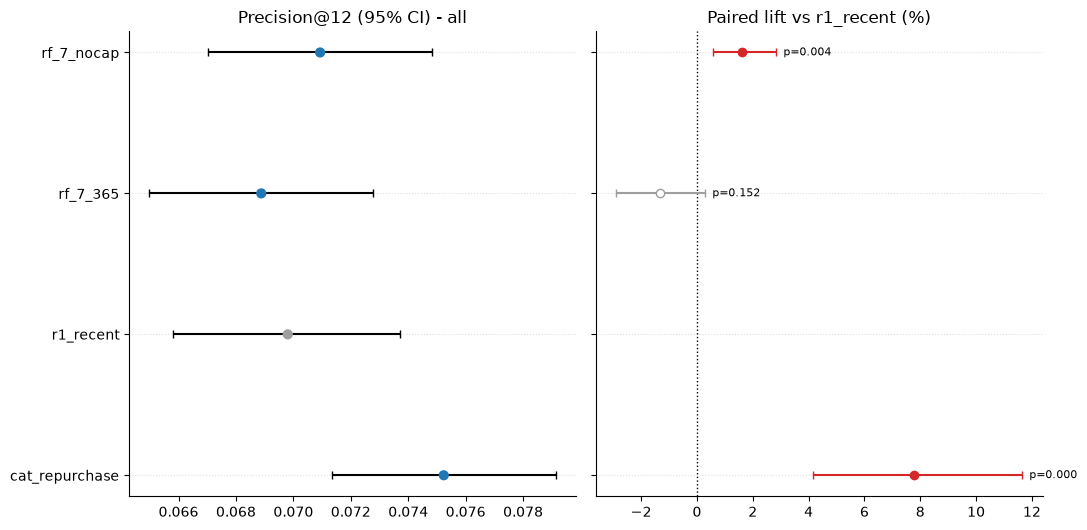

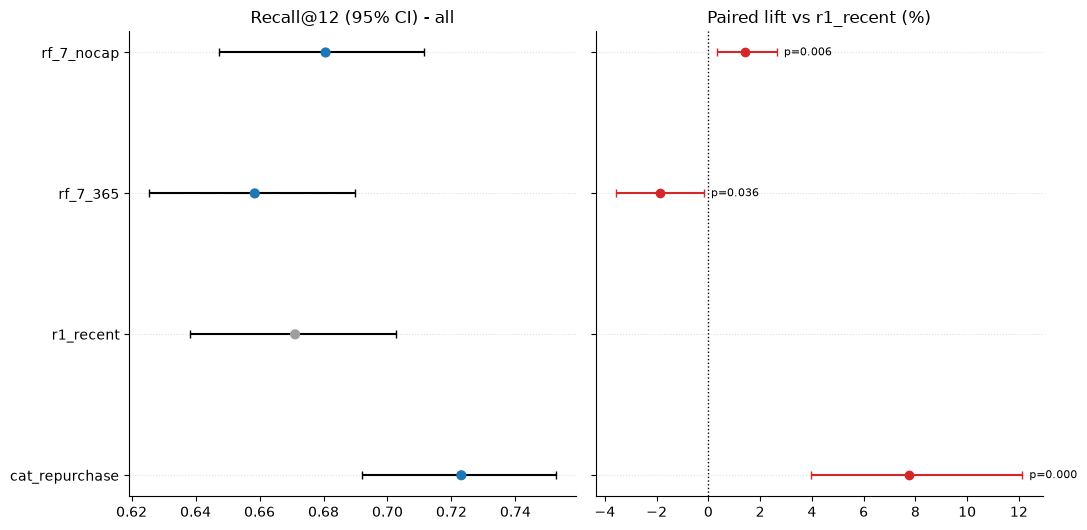

In [9]:
metrics=["HIT@12", "Precision@12", "Recall@12"]
for m in metrics:
    plot_bootstrap(ci_df, paired_df,baseline="r1_recent", metric= m, save_path=f"figures/ci_paired_ci_{m}@12")

### MORE INSIGHTS: CATEGORY RATEs

`category_rates` is a method of `cat_repurchase` model - the process is the model steps back a week from the anchor. For every (customer, article) pair, it measures the age at that point and checks whether the customer bought that article again in the following week.

OUTPUT:
* `category_rates()`: each cell is the (smoothed) probability that a pair of that category and age gets re-bought in a week.
* `category_rates("pairs")`: how many pairs the cell was measured on, which is its sample size.

*Notes*: Using both outputs give you a solid answer about **"what is the probability of a customer re-buying an article within a category in the following week? And to what extent can we trust it? (pair)"**:
* category_rates -> the probability of an article belonging to a category (such as trousers) getting re-bought the following week
* category_rates(pair) -> whether to trust by looking it a pair size - sample size ; the bigger the size, the more credible the result

In [8]:
# investigate more
models["cat_repurchase"].category_rates()       # learned repeat rate per category x age bucket

,<=3d,4-7d,8-14d,15-30d,31-60d,61-90d,91-180d,>180d
category,,,,,,,,
-1,0.010587,0.019851,0.000569,0.002450,0.001211,0.000015,0.000856,1.177943e-03
49,0.031232,0.011167,0.004983,0.001965,0.000623,0.000305,0.000219,2.366874e-05
57,0.036453,0.008437,0.007022,0.000081,0.000010,0.000005,0.000002,1.004356e-07
59,0.018399,0.009968,0.001574,0.000564,0.000361,0.000001,0.000275,2.950426e-08
60,0.031232,0.011167,0.004983,0.001876,0.000542,0.000265,0.000219,3.232803e-05
...,...,...,...,...,...,...,...,...
515,0.031232,0.011167,0.004983,0.002063,0.000594,0.000254,0.000184,3.398588e-05
525,0.031232,0.011167,0.004983,0.002063,0.000594,0.000305,0.000285,6.311663e-05
761,0.031232,0.010635,0.004983,0.001965,0.000567,0.000142,0.000238,6.627246e-05


In [9]:
models["cat_repurchase"].category_rates("pairs")    # how many pairs each cell is based on

,<=3d,4-7d,8-14d,15-30d,31-60d,61-90d,91-180d,>180d
category,,,,,,,,
-1,39,92,155,405,816,394,1155,1679
49,0,0,0,1,0,0,6,36
57,52,125,279,492,1248,1332,2436,13177
59,177,504,1314,1827,5557,5886,10922,44904
60,0,0,0,2,3,3,6,21
...,...,...,...,...,...,...,...,...
512,1,0,1,5,0,0,0,0
515,0,0,0,0,1,4,11,19
525,0,0,0,0,1,0,0,1


### **CONCLUSION**
* it seems like category_repurchase wins obviously -> stress-test it
* the recency-frequency model win is inconsistent throughout parameters → test it as well → to see whether frequency adds any value

### **CATEGORY-REPURCHASE IN-DEPTH**

In [21]:
# ablation test: does the category matter at all? - category
# By removing the signal of category -> we'll test whether it truly exists and matters on the dataset
one = pd.Series("all", index=types.index)             # every article in a single category

In [23]:
models = {
    "r1_recent": R1RecentModel(),
    "cat_repurchase": CategoryRepurchaseModel(types),             # what ran
    "age_only": CategoryRepurchaseModel(one),                     # age buckets, no categories
    "cat_s200": CategoryRepurchaseModel(types, smoothing=200),
    "cat_s1000": CategoryRepurchaseModel(types, smoothing=1000),
}

#age here means how many days since the last time the customer bought this specific category? Which works "as-if" similarly to r1_recent - the recent the day, the higher the score.

In [24]:
summary, per_user = compare_models(models, train, val, baseline="r1_recent", problem="buy_again", k=12)

Setup: user_group=warm, truth_mode=repeat -> 813 users, 1,022 relevant purchases
        0.0% of relevant purchases are articles never seen in history (no history-based model can reach them)
Evaluating r1_recent ...
Evaluating cat_repurchase ...
Evaluating age_only ...
Evaluating cat_s200 ...
Evaluating cat_s1000 ...


In [25]:
summary

,HIT@12,Precision@12,Recall@12,coverage,n_users,fit_s,recommend_s,catalog_cov,reach,head_share,HIT@12 lift %,Precision@12 lift %,Recall@12 lift %
r1_recent,0.698647,0.069803,0.671112,1.0,813.0,2.1,0.0,0.078031,0.909980,0.144902,0.000000,0.000000,0.000000
cat_repurchase,0.745387,0.075236,0.723080,1.0,813.0,6.4,0.0,0.074418,0.909002,0.183550,6.690141,7.782673,7.743566
age_only,0.698647,0.069803,0.671112,1.0,813.0,6.9,0.0,0.078031,0.909980,0.144902,0.000000,0.000000,0.000000
cat_s200,0.746617,0.075338,0.723490,1.0,813.0,6.9,0.0,0.074733,0.912916,0.181678,6.866197,7.929515,7.804659
cat_s1000,0.755228,0.076056,0.732715,1.0,813.0,6.1,0.0,0.074930,0.918787,0.180467,8.098592,8.957416,9.179256


the category actually gives signal, rather than coming from another source (like age)

Let's examine it with the `truth` in our dataset - to understand more visually how do each model hit:
* `hits_by_age` examines "where do the hits come from?" by taking the model's top 12 per user, then keep the (user, article) pairs that are suitable for built truth, also cut hits into age bins to see more clearly
* `hit_pairs` examines **gain & lost** hits between two models as a set of pairs. Gained means model A hit the pair and model B didn’t, and lost is the reverse => very strong in terms of unit comparison

In [10]:
truth = build_truth(val, train, user_group="warm", truth_mode="repeat")
anchor = val["t_dat"].min()
last = train.groupby(["customer_id", "article_id"])["t_dat"].max().rename("last").reset_index()
users = truth["customer_id"].unique()

In [11]:
def hits_by_age(model):
    recs = model.recommend(users=users, k=12)
    hits = recs.merge(truth, on=["customer_id", "article_id"]).merge(last, on=["customer_id", "article_id"])
    age = (anchor - hits["last"]).dt.days
    bins = pd.cut(age, [0, 7, 30, 90, 180,365, 100_000], labels=["<=7d", "8-30d", "31-90d", "91-180d", "181-365d", ">365d"])
    return bins.value_counts().sort_index()

In [12]:
pd.DataFrame({name: hits_by_age(models[name]) for name in ["r1_recent", "cat_repurchase", "rf_7_nocap", "rf_7_365"]})

,r1_recent,cat_repurchase,rf_7_nocap,rf_7_365
last,,,,
<=7d,324,325,327,327
8-30d,145,143,143,143
31-90d,99,96,103,103
91-180d,49,75,50,50
181-365d,45,59,49,49
>365d,19,36,20,0


In [17]:
def hit_pairs(model):
    recs = model.recommend(users=users, k=12)
    return recs.merge(truth, on=["customer_id", "article_id"])[["customer_id", "article_id"]]

h_cat, h_r1 = hit_pairs(models["cat_repurchase"]), hit_pairs(models["r1_recent"])
key = ["customer_id", "article_id"]
gained = h_cat.merge(h_r1.assign(r1=1), how="left", on=key).query("r1.isna()")    # only cat_repurchase hit
lost = h_r1.merge(h_cat.assign(cat=1), how="left", on=key).query("cat.isna()")    # only r1_recent hit
print(f"gained {len(gained)} hits, lost {len(lost)} hits")
print(pd.DataFrame({"gained": gained["article_id"].map(types).value_counts(),
                    "lost": lost["article_id"].map(types).value_counts()}).fillna(0).astype(int)
        .sort_values("gained", ascending=False).head(10))

TypeError: hit_pairs() missing 2 required positional arguments: 'users' and 'truth'

Let's select `product_type_no` within [272, 255, 304, 286, 302, 262] to test

Especially the **272** we need to check how concentrated the gain is -> If the 51 hits come from only a handful of users or one or two articles, the gain is fragile. If they are spread across many users and articles, it is more credible.

In [15]:
articles.loc[articles["product_type_no"].isin([272, 255, 304, 286, 302, 262]),
             ["product_type_no", "product_type_name", "product_group_name"]].drop_duplicates()

g272 = gained[gained["article_id"].map(types) == 272]
print("hits:", len(g272), "| distinct users:", g272["customer_id"].nunique(),
      "| distinct articles:", g272["article_id"].nunique())
print(g272["article_id"].value_counts().head(5))
print((anchor - g272.merge(last, on=["customer_id", "article_id"])["last"]).dt.days.describe())

# final result: hits: 51 | distinct users: 48 | distinct articles: 40
# => credible

hits: 51 | distinct users: 48 | distinct articles: 40
article_id
0448509014    4
0706016015    3
0706016003    3
0714790020    2
0706016001    2
Name: count, dtype: int64
count     51.000000
mean     220.078431
std      156.298668
min        2.000000
25%       80.500000
50%      180.000000
75%      339.000000
max      569.000000
Name: last, dtype: float64


In [18]:
# Let's look more on the cross-validate through different validation weeks
# P1: Does the gain repeat? That is the HIT lift and the net hits per week.
key = ["customer_id", "article_id"]
watch = [272, 255, 265]                 # categories to follow

def hit_pairs_v2(model, users, truth, k=12):
    recs = model.recommend(users=users, k=k)
    return recs.merge(truth, on=key)[key]

rows, ratios = [], []
for shift in (0, 7, 14, 21):            # 0 = the validation week you already ran
    if shift == 0:
        train_s, val_s = train, val
    else:
        cut = val["t_dat"].min() - pd.Timedelta(days=shift)
        train_s = train[train["t_dat"] < cut]
        val_s = train[(train["t_dat"] >= cut) & (train["t_dat"] < cut + pd.Timedelta(days=7))]

    s, _ = compare_models(models, train_s, val_s, baseline="r1_recent", problem="buy_again", k=12)

    truth_s = build_truth(val_s, train_s, user_group="warm", truth_mode="repeat")
    users_s = truth_s["customer_id"].unique()
    h_cat = hit_pairs_v2(models["cat_repurchase"], users_s, truth_s)
    h_r1 = hit_pairs_v2(models["r1_recent"], users_s, truth_s)
    gained = h_cat.merge(h_r1.assign(r1=1), how="left", on=key).query("r1.isna()")
    lost = h_r1.merge(h_cat.assign(c=1), how="left", on=key).query("c.isna()")
    net = gained["article_id"].map(types).value_counts().sub(
        lost["article_id"].map(types).value_counts(), fill_value=0)

    rows.append({"shift": shift, "val_start": val_s["t_dat"].min().date(),
                 "HIT_r1": s.loc["r1_recent", "HIT@12"], "HIT_cat": s.loc["cat_repurchase", "HIT@12"],
                 "lift_%": s.loc["cat_repurchase", "HIT@12 lift %"], "net_hits": len(gained) - len(lost),
                 **{f"net_{c}": net.get(c, 0) for c in watch}})

    rates = models["cat_repurchase"].category_rates()               # what this fit learned
    ratio = rates.reindex(watch).div(rates.loc["ALL"], axis=1)       # multiples of the overall repeat rate
    ratios.append(ratio.assign(shift=shift).set_index("shift", append=True))

print(pd.DataFrame(rows).round(4).to_string(index=False))
print("\nlearned repeat rate as a multiple of the overall rate (per fit):")
print(pd.concat(ratios).swaplevel().sort_index().round(2).iloc[:, :8].to_string())

Setup: user_group=warm, truth_mode=repeat -> 813 users, 1,022 relevant purchases
        0.0% of relevant purchases are articles never seen in history (no history-based model can reach them)
Evaluating r1_recent ...
Evaluating rf_7_nocap ...
Evaluating rf_7_365 ...
Evaluating cat_repurchase ...
Setup: user_group=warm, truth_mode=repeat -> 497 users, 674 relevant purchases
        0.0% of relevant purchases are articles never seen in history (no history-based model can reach them)
Evaluating r1_recent ...
Evaluating rf_7_nocap ...
Evaluating rf_7_365 ...
Evaluating cat_repurchase ...
Setup: user_group=warm, truth_mode=repeat -> 521 users, 762 relevant purchases
        0.0% of relevant purchases are articles never seen in history (no history-based model can reach them)
Evaluating r1_recent ...
Evaluating rf_7_nocap ...
Evaluating rf_7_365 ...
Evaluating cat_repurchase ...
Setup: user_group=warm, truth_mode=repeat -> 511 users, 662 relevant purchases
        0.0% of relevant purchases ar

In [23]:
pd.DataFrame(rows).round(4)

,shift,val_start,HIT_r1,HIT_cat,lift_%,net_hits,net_272,net_255,net_265
0,0,2020-08-26,0.6986,0.7454,6.6901,53,51.0,8.0,0.0
1,7,2020-08-19,0.8068,0.7847,-2.7431,-10,2.0,4.0,0.0
2,14,2020-08-12,0.7869,0.7735,-1.7073,-6,2.0,6.0,1.0
3,21,2020-08-05,0.7710,0.7710,0.0000,-5,4.0,-2.0,2.0


In [25]:
pd.concat(ratios).swaplevel().sort_index().round(2).iloc[:, :8]

<=3d  4-7d  8-14d  15-30d  31-60d  61-90d  91-180d  >180d
shift category                                                           
0     255       0.37  1.48   1.51    1.20    1.72    1.80     2.02   0.80
      265       0.92  1.33   0.80    1.02    0.80    0.46     0.35   0.11
      272       1.92  1.43   1.80    1.48    2.50    3.07     1.74   3.24
7     255       1.20  0.69   1.52    1.55    2.04    0.00     1.48   1.11
      265       0.92  1.03   0.98    0.84    0.86    0.60     0.80   0.20
      272       1.09  1.36   1.48    1.21    1.70    1.14     1.09   2.36
14    255       0.27  0.73   2.10    1.79    2.42    1.23     0.66   2.69
      265       1.21  1.73   1.12    1.07    1.09    1.05     0.36   0.34
      272       1.08  1.32   1.23    1.27    0.89    0.57     1.70   1.86
21    255       0.43  1.34   0.42    1.00    0.80    0.85     1.77   2.32
      265       1.79  0.77   0.98    1.96    1.76    1.36     1.03   0.59
      272       1.15  1.11   0.98    1.43    1.56    1.23     2.14   1.82

### Ablation & Cross-Validation Analysis Summary

#### 1. Baseline Verification (`shift = 0`)
- **Status:** PASSED (100% match)
- **Metrics:** `HIT@12 lift%` = +6.6901%, `net_hits` = +53, `net_272` = +51.
- **Confirmation:** Model pipeline logic and parameters are consistent.

#### 2. Temporal Cross-Validation Results

| Shift | Validation Start | HIT_r1 | HIT_cat | Lift (%) | Net Hits | Net 272 |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| 0 | 2020-08-26 | 0.6986 | 0.7454 | **+6.69** | **+53** | **+51.0** |
| 7 | 2020-08-19 | 0.8068 | 0.7847 | **-2.74** | **-10** | **+2.0** |
| 14 | 2020-08-12 | 0.7869 | 0.7735 | **-1.71** | **-6** | **+2.0** |
| 21 | 2020-08-05 | 0.7710 | 0.7710 | **0.00** | **-5** | **+4.0** |

#### 3. Findings & Verdict
- **Sign Instability:** Lift flips to negative across prior weeks (`shift 7, 14, 21`), failing the temporal stability criterion.
- **Concentration Collapse:** Category 272 gain drops sharply from +51 (`shift 0`) to +2~+4 in prior weeks.
- **Conclusion:** The +6.69% lift in `shift 0` is a **one-week artifact / temporal noise**, not a persistent feature.

### **RECENCY-FREQUENCY INDEPTH**

In [27]:
# setup pairs to delve more into the frequency-recency model
def build_pairs(history_df, anchor_date, article_type, horizon_days=7):
    cut = anchor_date - pd.Timedelta(days=horizon_days)
    past = history_df[history_df["t_dat"] < cut]
    future = history_df[history_df["t_dat"] >= cut]

    pairs = past.groupby(["customer_id", "article_id"], as_index=False).agg(
        last_date=("t_dat", "max"), n_purchase=("t_dat", "count"))
    again = future[["customer_id", "article_id"]].drop_duplicates().assign(repeated=1)
    pairs = pairs.merge(again, how="left", on=["customer_id", "article_id"])
    pairs["repeated"] = pairs["repeated"].fillna(0)
    pairs["age_days"] = (cut - pairs["last_date"]).dt.days
    pairs["category"] = pairs["article_id"].map(article_type)
    return pairs

pairs = build_pairs(train, val['t_dat'].min(), types)

In [29]:
pairs[pairs.repeated==1]

,customer_id,article_id,last_date,n_purchase,repeated,age_days,category
2920,179,0750422018,2020-07-29,1,1.0,21,272
5601,428,0835348001,2020-02-27,1,1.0,174,262
10836,809,0573085043,2020-06-05,2,1.0,75,272
11701,851,0769270001,2020-04-25,2,1.0,116,272
12305,909,0872901001,2020-08-18,1,1.0,1,259
...,...,...,...,...,...,...,...
1763678,135151,0898075002,2020-08-14,1,1.0,5,274
1763679,135151,0918474001,2020-08-14,1,1.0,5,267
1771932,135726,0854619002,2020-06-30,3,1.0,50,59
1775901,136021,0924228001,2020-08-16,1,1.0,3,262


In [35]:
# EDA 1: how much frequency variation is there?
pairs["freq"] = pairs["n_purchase"].clip(upper=4)          # 1,2,3,4+
pairs["freq"].value_counts(normalize=True).sort_index()

freq
1    0.837151
2    0.136113
3    0.017980
4    0.008756
Name: proportion, dtype: float64

In [36]:
# EDA 2: repeat rate by frequency
pairs.groupby("freq")["repeated"].agg(rate="mean", pairs="count").reset_index()

,freq,rate,pairs
0,1,0.000340,1489265
1,2,0.000496,242141
2,3,0.000969,31985
3,4,0.001027,15577


In [37]:
edges=[3, 7, 14, 30, 60, 90, 180]
pairs["bucket"] = pd.cut(pairs["age_days"], [-1] + edges + [1e9])
pairs.groupby(["bucket", "freq"], observed=True)["repeated"].mean().unstack().reset_index()

freq,bucket,1,2,3,4
0,"(-1.0, 3.0]",0.030158,0.034771,0.048000,0.032258
1,"(3.0, 7.0]",0.010032,0.013957,0.032110,0.017391
2,"(7.0, 14.0]",0.004894,0.005222,0.006349,0.006667
3,"(14.0, 30.0]",0.001848,0.003250,0.001344,0.006154
4,"(30.0, 60.0]",0.000514,0.000774,0.002989,0.004373
5,"(60.0, 90.0]",0.000292,0.000354,0.000000,0.001608
6,"(90.0, 180.0]",0.000235,0.000507,0.001137,0.000000
7,"(180.0, 1000000000.0]",0.000054,0.000096,0.000218,0.000439


### CONTEXT
Analysis of user-article purchase pairs to evaluate the marginal signal of purchase frequency (`n_purchase`) on the likelihood of a repeat purchase (`repeated`), both unconditionally and controlled for recency (`age`).

---

#### [EDA_1]: Frequency Distribution
**Metric:** Distribution of `n_purchase` per (user, article) pair prior to cut-off.

*   **freq_1:** 83.71%
*   **freq_2:** 13.61%
*   **freq_3:** 1.79%
*   **freq_4+:** 0.87%

**Observation:** Data is heavily right-skewed. The vast majority (~83.7%) of user-article interactions consist of single purchases. Feature variance is limited to the remaining ~16.3% of the dataset.

---

#### [EDA_2]: Unconditional Repeat Rate by Frequency
**Metric:** Repeat purchase rate grouped by `n_purchase` bucket.

| Frequency Bucket | Pair Count | Repeat Rate |
| :--- | :--- | :--- |
| 1 | 1,489,265 | 0.000340 (0.034%) |
| 2 | 242,141 | 0.000496 (0.049%) |
| 3 | 31,985 | 0.000969 (0.096%) |
| 4+ | 15,577 | 0.001027 (0.102%) |

**Observation:** There is a strict monotonic increase in repeat rate as frequency increases. The baseline probability is globally low (< 0.11%), but an item bought 4+ times has exactly a 3.02x higher probability of being repurchased compared to an item bought once.

---

#### [EDA_3]: Repeat Rate Controlled by Recency
**Metric:** Repeat purchase rate grouped by `age` (days since last purchase) and `n_purchase`.

| Age Bucket | Freq 1 Rate | Freq 2 Rate | Freq 3 Rate | Freq 4+ Rate |
| :--- | :--- | :--- | :--- | :--- |
| (-1.0, 3.0] | 0.030158 | 0.034771 | 0.048000 | 0.032258 |
| (3.0, 7.0] | 0.010032 | 0.013957 | 0.032110 | 0.017391 |
| (7.0, 14.0] | 0.004894 | 0.005222 | 0.006349 | 0.006667 |
| (14.0, 30.0] | 0.001848 | 0.003250 | 0.001344 | 0.006154 |
| (30.0, 60.0] | 0.000514 | 0.000774 | 0.002989 | 0.004373 |
| (60.0, 90.0] | 0.000292 | 0.000354 | 0.000000 | 0.001608 |
| (90.0, 180.0] | 0.000235 | 0.000507 | 0.001137 | 0.000000 |
| (180.0, max] | 0.000054 | 0.000096 | 0.000218 | 0.000439 |

**Observations:**
1.  **Recency Dominance (Vertical Trend):** Repeat rate decays exponentially as `age` increases across all frequency buckets (e.g., Freq 1 drops from ~3.01% at <3 days to ~0.005% at >180 days).
2.  **Frequency Isolation (Horizontal Trend):** Controlling for recency, the positive correlation between `n_purchase` and repeat rate generally persists within the age buckets.
3.  **Edge-case Variance:** Non-monotonic fluctuations in high-frequency/low-recency buckets (e.g., Freq 4 dropping in the 3-day and 7-day windows, or dropping to 0 in the 90-180 day window for Freq 3/4) indicate noise stemming from extremely low sample sizes in those specific intersections. The marginal signal of frequency is most clearly isolated and stable in the older recency buckets (e.g., 7-14 days and >180 days).

### **CONCLUSION**
* Frequency carries a real but modest marginal signal. The 3.0× rise is monotonic overall, and it mostly survives the recency control.
* Recency dominates by a wide margin. Repeat rates run from about 3% in the first few days to under 0.01% after 180 days, so a difference between frequency buckets is small next to the difference between age buckets.
* Only about 16% of pairs have any frequency variation, so the feature can only reorder a minority of a user’s list.

Purchase frequency shows a monotonic positive association with repeat probability (0.034% for single purchases to 0.103% for 4+), which largely persists within age buckets. However, recency dominates by orders of magnitude, 84% of pairs are single purchases, and the frequency effect is clearest in older age buckets where few repeats occur. Given the project scope, we retain category_repurchase without a frequency term. Adding a frequency bucket to the rate table is left as future work.